In [4]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from game.game_engine import GameEngine
from agents.mcts_agent import MCTSAgent

# Các mức Simulation Budget
SIMULATION_BUDGETS = [100, 500, 1000, 2000]

# Số trạng thái kiểm thử
N_STATES = 20

# Thư mục lưu kết quả
OUTPUT_DIR = r"D:\TTNTNC\TicTacToe_AI\results\mcts_budget_analysis"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Khởi tạo thành công!")

Khởi tạo thành công!


In [5]:
rng = random.Random(2026)

test_positions = []

for state_id in range(N_STATES):

    game = GameEngine(
        board_size=4,
        win_length=4
    )

    game.reset()

    target_plies = rng.randint(3, 7)

    for _ in range(target_plies):

        if game.is_terminal():
            break

        legal_actions = game.legal_actions()

        if not legal_actions:
            break

        action = rng.choice(legal_actions)
        game.step(action)

    # Chỉ lấy trạng thái chưa kết thúc
    if not game.is_terminal():

        test_positions.append({
            "state_id": state_id + 1,
            "plies": target_plies,
            "game": game.clone()
        })

print("Đã tạo:", len(test_positions), "trạng thái")

assert len(test_positions) == N_STATES, (
    f"Chỉ tạo được {len(test_positions)} trạng thái, "
    f"cần kiểm tra lại GameEngine."
)

Đã tạo: 20 trạng thái


In [6]:
for position in test_positions:

    print(f"\nState ID: {position['state_id']}")
    print(f"Số lượt đã đi: {position['plies']}")

    position["game"].render()


State ID: 1
Số lượt đã đi: 3

State ID: 2
Số lượt đã đi: 3

State ID: 3
Số lượt đã đi: 7

State ID: 4
Số lượt đã đi: 6

State ID: 5
Số lượt đã đi: 3

State ID: 6
Số lượt đã đi: 6

State ID: 7
Số lượt đã đi: 6

State ID: 8
Số lượt đã đi: 5

State ID: 9
Số lượt đã đi: 7

State ID: 10
Số lượt đã đi: 6

State ID: 11
Số lượt đã đi: 6

State ID: 12
Số lượt đã đi: 6

State ID: 13
Số lượt đã đi: 7

State ID: 14
Số lượt đã đi: 4

State ID: 15
Số lượt đã đi: 6

State ID: 16
Số lượt đã đi: 7

State ID: 17
Số lượt đã đi: 3

State ID: 18
Số lượt đã đi: 7

State ID: 19
Số lượt đã đi: 6

State ID: 20
Số lượt đã đi: 3


In [7]:
mcts_records = []

total_runs = len(SIMULATION_BUDGETS) * len(test_positions)
run_count = 0

for budget in SIMULATION_BUDGETS:

    print(f"\nĐang kiểm tra MCTS với {budget} simulations...")

    agent = MCTSAgent(simulations=budget)

    for position in test_positions:

        run_count += 1

        # Tạo bản sao để không làm thay đổi trạng thái gốc
        game_copy = position["game"].clone()

        # Cố định seed để thí nghiệm có thể tái lập
        current_seed = 2026 + position["state_id"]
        random.seed(current_seed)
        np.random.seed(current_seed)

        # MCTS lựa chọn nước đi
        action = agent.choose_action(game_copy)

        # Lấy thống kê sau khi tìm kiếm
        stats = agent.get_search_stats()

        mcts_records.append({
            "Simulation_Budget": budget,
            "State_ID": position["state_id"],
            "Plies": position["plies"],
            "Action": str(action),

            "Simulations_Completed": stats["simulations_completed"],
            "Nodes_Created": stats["nodes_created"],
            "Tree_Nodes_Visited": stats["tree_nodes_visited"],
            "Rollout_Steps": stats["rollout_steps"],

            "Decision_Time": stats["decision_time"],
            "Simulations_Per_Second": stats["simulations_per_second"]
        })

        print(
            f"\rTiến độ: {run_count}/{total_runs}",
            end=""
        )

print("\nHoàn thành thí nghiệm!")


Đang kiểm tra MCTS với 100 simulations...
Tiến độ: 20/80
Đang kiểm tra MCTS với 500 simulations...
Tiến độ: 40/80
Đang kiểm tra MCTS với 1000 simulations...
Tiến độ: 60/80
Đang kiểm tra MCTS với 2000 simulations...
Tiến độ: 80/80
Hoàn thành thí nghiệm!


In [8]:
mcts_budget_df = pd.DataFrame(mcts_records)

mcts_budget_summary = (
    mcts_budget_df
    .groupby("Simulation_Budget")
    .agg(
        Total_Runs=("State_ID", "count"),

        Mean_Simulations=("Simulations_Completed", "mean"),

        Mean_Nodes_Created=("Nodes_Created", "mean"),

        Mean_Tree_Nodes_Visited=("Tree_Nodes_Visited", "mean"),

        Mean_Rollout_Steps=("Rollout_Steps", "mean"),

        Mean_Decision_Time=("Decision_Time", "mean"),
        Median_Decision_Time=("Decision_Time", "median"),
        Max_Decision_Time=("Decision_Time", "max"),

        Mean_Simulations_Per_Second=("Simulations_Per_Second", "mean")
    )
    .reset_index()
)

display(mcts_budget_summary.round(4))

# Lưu kết quả
mcts_budget_df.to_csv(
    os.path.join(OUTPUT_DIR, "mcts_budget_raw.csv"),
    index=False,
    encoding="utf-8-sig"
)

mcts_budget_summary.to_csv(
    os.path.join(OUTPUT_DIR, "mcts_budget_summary.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu dữ liệu MCTS.")

,Simulation_Budget,Total_Runs,Mean_Simulations,Mean_Nodes_Created,Mean_Tree_Nodes_Visited,Mean_Rollout_Steps,Mean_Decision_Time,Median_Decision_Time,Max_Decision_Time,Mean_Simulations_Per_Second
0,100,20,100.0,100.15,198.20,728.90,0.0180,0.0162,0.0502,6042.4400
1,500,20,500.0,489.50,1379.75,3199.55,0.0840,0.0831,0.1291,6114.7615
2,1000,20,1000.0,961.75,3055.15,6074.40,0.1709,0.1702,0.2364,6069.6561
3,2000,20,2000.0,1895.00,6804.95,11393.75,0.3678,0.3583,0.4945,5577.7027


Đã lưu dữ liệu MCTS.


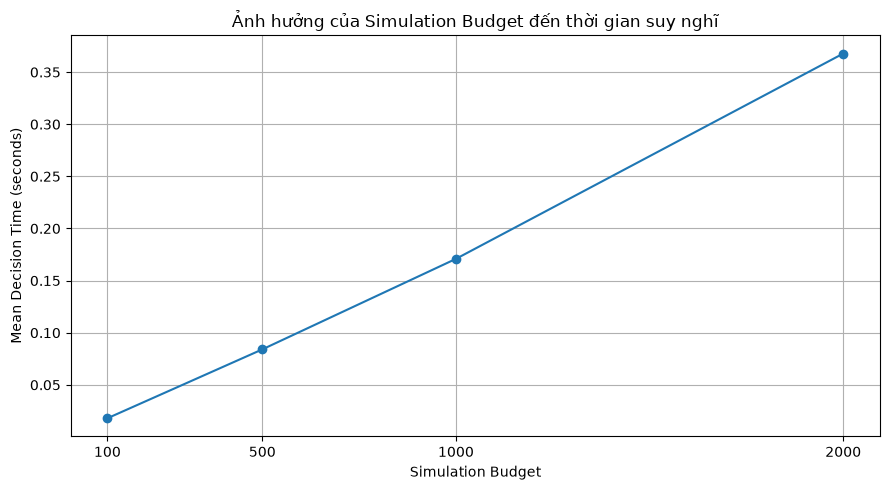

In [9]:
plt.figure(figsize=(9, 5))

plt.plot(
    mcts_budget_summary["Simulation_Budget"],
    mcts_budget_summary["Mean_Decision_Time"],
    marker="o"
)

plt.xlabel("Simulation Budget")
plt.ylabel("Mean Decision Time (seconds)")
plt.title("Ảnh hưởng của Simulation Budget đến thời gian suy nghĩ")
plt.xticks(SIMULATION_BUDGETS)
plt.grid(True)
plt.tight_layout()
plt.show()

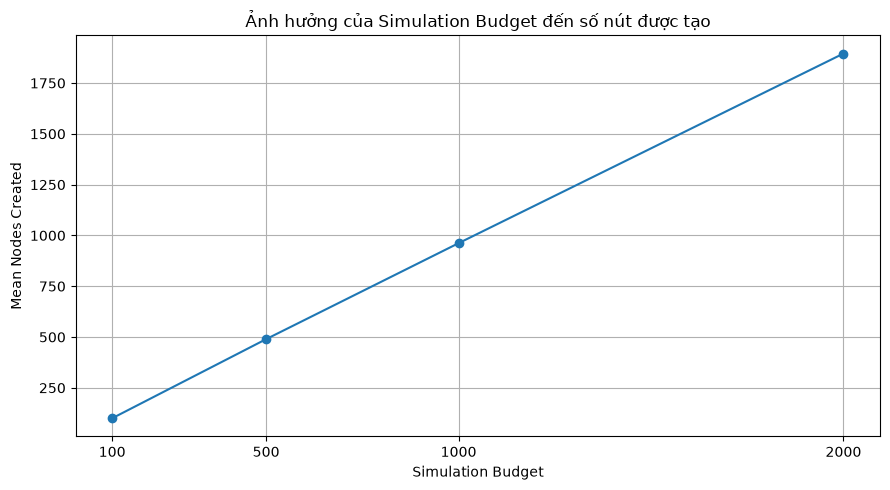

In [10]:
plt.figure(figsize=(9, 5))

plt.plot(
    mcts_budget_summary["Simulation_Budget"],
    mcts_budget_summary["Mean_Nodes_Created"],
    marker="o"
)

plt.xlabel("Simulation Budget")
plt.ylabel("Mean Nodes Created")
plt.title("Ảnh hưởng của Simulation Budget đến số nút được tạo")
plt.xticks(SIMULATION_BUDGETS)
plt.grid(True)
plt.tight_layout()
plt.show()

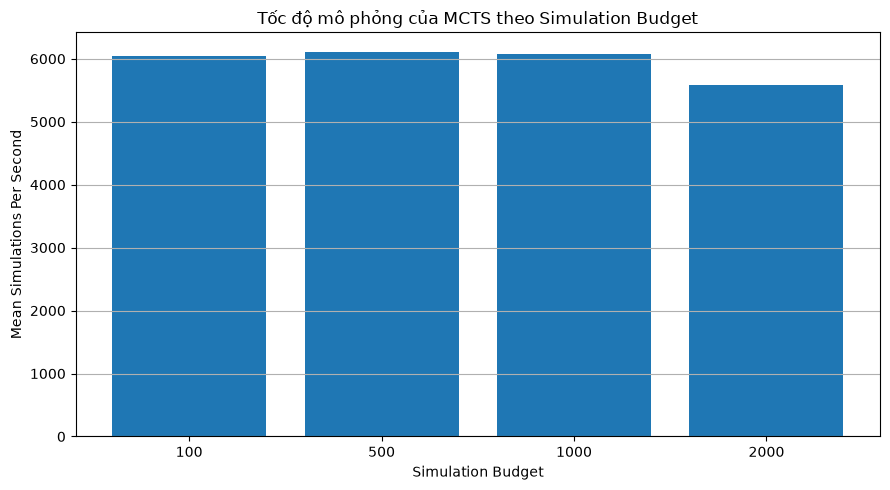

In [11]:
plt.figure(figsize=(9, 5))

plt.bar(
    mcts_budget_summary["Simulation_Budget"].astype(str),
    mcts_budget_summary["Mean_Simulations_Per_Second"]
)

plt.xlabel("Simulation Budget")
plt.ylabel("Mean Simulations Per Second")
plt.title("Tốc độ mô phỏng của MCTS theo Simulation Budget")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [12]:
action_pivot = mcts_budget_df.pivot(
    index="State_ID",
    columns="Simulation_Budget",
    values="Action"
)

display(action_pivot)

reference_actions = action_pivot[2000]

agreement_records = []

for budget in SIMULATION_BUDGETS:

    same_actions = (
        action_pivot[budget] == reference_actions
    ).sum()

    total_states = len(action_pivot)

    agreement_records.append({
        "Simulation_Budget": budget,
        "Same_Action_Count": same_actions,
        "Total_States": total_states,
        "Agreement_Percentage": same_actions / total_states * 100
    })

agreement_df = pd.DataFrame(agreement_records)

display(agreement_df.round(2))

Simulation_Budget,100,500,1000,2000
State_ID,,,,
1,"(0, 1)","(1, 1)","(1, 2)","(1, 0)"
2,"(0, 3)","(1, 2)","(3, 1)","(2, 1)"
3,"(0, 0)","(1, 1)","(0, 0)","(0, 0)"
4,"(3, 3)","(3, 3)","(3, 3)","(3, 3)"
5,"(0, 3)","(0, 1)","(3, 0)","(3, 0)"
6,"(3, 3)","(3, 0)","(3, 0)","(3, 0)"
7,"(3, 3)","(3, 2)","(3, 2)","(3, 2)"
8,"(1, 2)","(1, 2)","(0, 0)","(1, 2)"
9,"(0, 1)","(2, 0)","(3, 0)","(2, 0)"


,Simulation_Budget,Same_Action_Count,Total_States,Agreement_Percentage
0,100,5,20,25.0
1,500,11,20,55.0
2,1000,12,20,60.0
3,2000,20,20,100.0


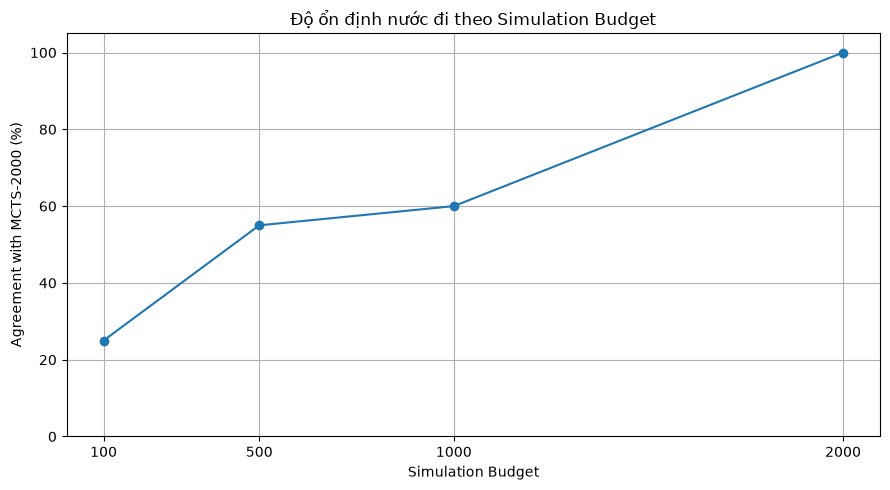

In [13]:
plt.figure(figsize=(9, 5))

plt.plot(
    agreement_df["Simulation_Budget"],
    agreement_df["Agreement_Percentage"],
    marker="o"
)

plt.xlabel("Simulation Budget")
plt.ylabel("Agreement with MCTS-2000 (%)")
plt.title("Độ ổn định nước đi theo Simulation Budget")
plt.xticks(SIMULATION_BUDGETS)
plt.ylim(0, 105)
plt.grid(True)
plt.tight_layout()
plt.show()

In [14]:
excel_path = os.path.join(
    OUTPUT_DIR,
    "mcts_simulation_budget_report.xlsx"
)

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:

    mcts_budget_df.to_excel(
        writer,
        sheet_name="Raw Results",
        index=False
    )

    mcts_budget_summary.to_excel(
        writer,
        sheet_name="Budget Summary",
        index=False
    )

    agreement_df.to_excel(
        writer,
        sheet_name="Action Agreement",
        index=False
    )

    action_pivot.to_excel(
        writer,
        sheet_name="Action Comparison"
    )

print("Đã xuất báo cáo:", excel_path)

Đã xuất báo cáo: D:\TTNTNC\TicTacToe_AI\results\mcts_budget_analysis\mcts_simulation_budget_report.xlsx
